# CI failure prediction on GitHub Actions - CART decision tree

Trains and evaluates the from-scratch CART tree (`tree/cart.py`, Breiman et al., 1984) on the **pooled** dataset (the enabled targets of `config/targets.json`, analysed as one CI workflow), with the frozen feature lists from `feature_selection.ipynb`.

**Protocol.** The dev segment (first 20% of the pooled runs) is followed by 5 expanding-window folds. Each train set is dev + the window so far; its last 20% is the **validation** tail. The hyperparameters, the pruning alpha and the decision threshold are chosen on validation only (`tree/tune.py`); each test fold is read once, after the tree is final.

**Per source.** Each fold's test rows are also scored per source: `run_cv` adds one row per fold and source next to the pooled row (`source = "all"`). The model is the same; only the scored rows differ.

**Targets.** T2 (runs whose previous run in the same lineage passed, or that open a lineage) is the main target; T1 (all runs) is secondary, for the comparison with Parrot.

**Baselines.** Parrot (previous outcome of the same lineage; on T2 always "pass"), majority class, and sklearn's `DecisionTreeClassifier` with the same choices per fold (a reference for the implementation, not a competitor).

**Random forest.** Section 9 repeats the CV with a forest of 100 bagged CART trees (`tree/forest.py`, Breiman, 2001): a stronger but not explainable comparison point.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import Markdown, display
from sklearn.metrics import matthews_corrcoef
from sklearn.tree import DecisionTreeClassifier
import json

from acise_p2_cidt.analysis import features as fs
from acise_p2_cidt.analysis.features import load_features
from acise_p2_cidt.collect.targets import load_targets, slug
from acise_p2_cidt.data.load import load, pool_name, repo_of, subset
from acise_p2_cidt.metrics.metrics import majority, parrot
from acise_p2_cidt.stats import tests as st
from acise_p2_cidt.training.cv import dev_split, folds, prepare, run_cv
from acise_p2_cidt.tree import forest, tune
from acise_p2_cidt.tree.cart import CART
from acise_p2_cidt.validate.live import MODEL_DIR
from acise_p2_cidt.viz import plots

SOURCES = [slug(c.target) for c in load_targets()]
DATASET = pool_name(SOURCES)
TARGETS = ("T2", "T1")
METRICS = ["mcc", "f1", "precision", "recall", "accuracy", "pct_builds_saved", "pct_failures_caught"]
data = {t: load(SOURCES, t) for t in TARGETS}
feats = {t: load_features(t, DATASET) for t in TARGETS}
fold_lists = {t: folds(data[t]) for t in TARGETS}
splits = {t: [prepare(data[t], feats[t], f) for f in fold_lists[t]] for t in TARGETS}
display(
    Markdown(f"**Pooled dataset `{DATASET}`** ({len(SOURCES)} sources): rows, failures, dev rows and frozen features per target"),
    pd.DataFrame(
        {
            t: {
                "rows": ds.meta["n_rows"],
                "failed": ds.meta["n_failed"],
                "fail_%": round(100 * ds.y.mean(), 2),
                "dev_rows": ds.meta["n_dev"],
                "features": len(feats[t]),
            }
            for t, ds in data.items()
        }
    ),
)

**Pooled dataset `pool-67fa17e1`** (13 sources): rows, failures, dev rows and frozen features per target

,T2,T1
rows,118748.00,150535.0
failed,19724.00,37181.0
fail_%,16.61,24.7
dev_rows,23749.00,30107.0
features,18.00,20.0


## 1. CART walkthrough (T2, dev split)

One tree on the dev split (head of dev = fit rows, tail = validation), depth 3, `class_weight="balanced"`. Each internal node is a test `x <= t` in raw units (no scaling); each leaf gives P(fail) as the weighted share of failed runs that reach it.

In [2]:
dev = dev_split(data["T2"], feats["T2"])
demo = CART(max_depth=3, min_samples_leaf=10, class_weight="balanced").fit(dev.X_fit, dev.y_fit)
print(f"depth {demo.depth_}, leaves {demo.n_leaves_}\n")
print(demo.export_text())

depth 3, leaves 8

|--- fail_rate_24h <= 0.34628
|   |--- event_push <= 0.5
|   |   |--- file_fail_prob_max <= 0.366432
|   |   |   |--- leaf: P(fail) = 0.40 from 3642 runs
|   |   |--- file_fail_prob_max > 0.366432
|   |   |   |--- leaf: P(fail) = 0.56 from 3177 runs
|   |--- event_push > 0.5
|   |   |--- file_fail_prob_max <= 0.20794
|   |   |   |--- leaf: P(fail) = 0.10 from 2512 runs
|   |   |--- file_fail_prob_max > 0.20794
|   |   |   |--- leaf: P(fail) = 0.27 from 2739 runs
|--- fail_rate_24h > 0.34628
|   |--- author_prior_fail_rate <= 0.440927
|   |   |--- event_pull_request <= 0.5
|   |   |   |--- leaf: P(fail) = 0.24 from 1254 runs
|   |   |--- event_pull_request > 0.5
|   |   |   |--- leaf: P(fail) = 0.64 from 2564 runs
|   |--- author_prior_fail_rate > 0.440927
|   |   |--- author_prior_commits <= 6223.5
|   |   |   |--- leaf: P(fail) = 0.77 from 2990 runs
|   |   |--- author_prior_commits > 6223.5
|   |   |   |--- leaf: P(fail) = 0.10 from 122 runs


`explain` gives the path of one run: the tests it passed, then the leaf. Shown for the first failed run of the validation tail.

fail_rate_24h = 0.413194 > 0.34628
author_prior_fail_rate = 0.521739 > 0.440927
author_prior_commits = 115 <= 6223.5
leaf: P(fail) = 0.77 from 2990 runs
actual: fail


[11/13/26 10:07:46] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_demo_T2.*

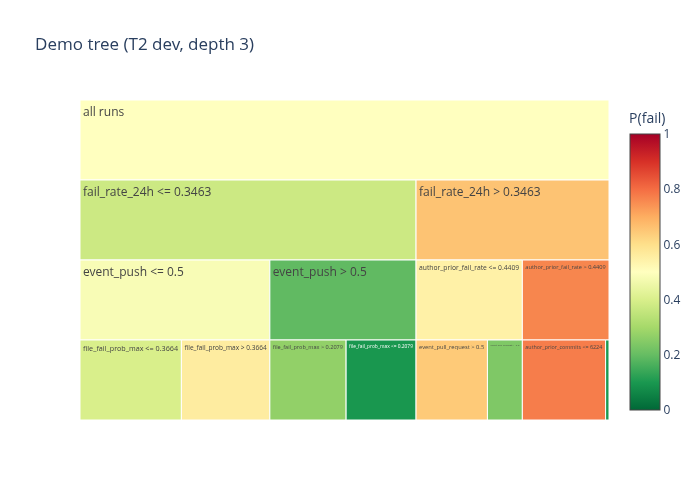

In [3]:
i = int(np.flatnonzero(dev.y_val.to_numpy())[0])
print("\n".join(demo.explain(dev.X_val.iloc[i])))
print("actual: fail")
plots.save(
    plots.tree_icicle(demo.tree_, demo.feature_names_, max_depth=3).update_layout(title="Demo tree (T2 dev, depth 3)"),
    "tree_demo_T2",
)

**Reference check.** sklearn's tree with the same parameters. When two splits have exactly the same gain, sklearn takes one at random (it shuffles the features), CART takes the first column, so the two trees can differ on ties only. `tests/test_cart.py` checks that every difference is such a tie. sklearn fits on float32, so its input is cast here.

In [4]:
X32 = dev.X_fit.astype("float32")
sk = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=0).fit(X32, dev.y_fit)
agree = np.mean(demo.predict(dev.X_fit) == sk.predict(X32).astype(bool))
print(f"root impurity: CART {demo.tree_.impurity[0]:.6f}, sklearn {sk.tree_.impurity[0]:.6f}")
print(f"leaves: CART {demo.n_leaves_}, sklearn {sk.get_n_leaves()}; training predictions agree on {agree:.1%}")

root impurity: CART 0.500000, sklearn 0.500000
leaves: CART 8, sklearn 8; training predictions agree on 100.0%


## 2. Overfitting control (T2)

**Depth.** In each CV fold, an unpruned tree per depth (`min_samples_leaf=10`, Gini, balanced), scored at threshold 0.5 on the fit rows and on the validation tail. A train line that keeps rising while the validation line stays flat is overfitting.

[11/13/26 10:08:15] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/tree_valcurve_depth_T2.*

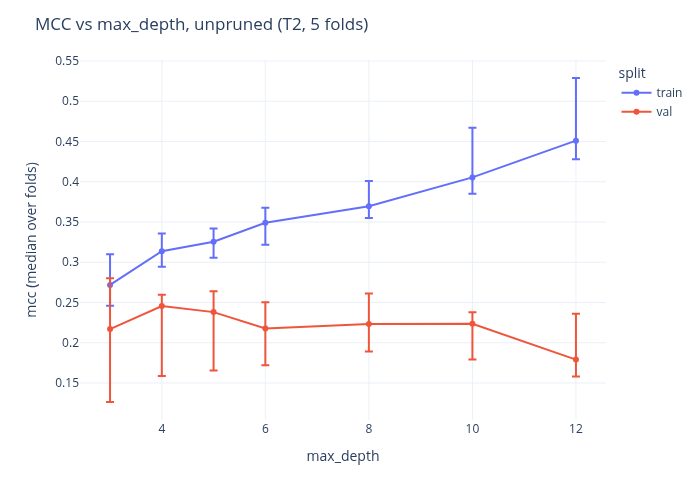

In [5]:
BASE = {"min_samples_leaf": 10, "criterion": "gini", "class_weight": "balanced"}
rows = []
for k, s in enumerate(splits["T2"]):
    for d in tune.GRID["max_depth"]:
        m = CART(max_depth=d, **BASE).fit(s.X_fit, s.y_fit)
        for name, X, y in (("train", s.X_fit, s.y_fit), ("val", s.X_val, s.y_val)):
            rows.append({"fold": k, "max_depth": d, "split": name, "mcc": matthews_corrcoef(y, m.predict(X))})
plots.save(
    plots.validation_curve(pd.DataFrame(rows), "max_depth").update_layout(title="MCC vs max_depth, unpruned (T2, 5 folds)"),
    "tree_valcurve_depth_T2",
)

**Pruning.** A depth-8 tree on the dev split, scored at every alpha of its cost-complexity path. `tune.choose_alpha` takes the alpha with the best validation MCC (ties: the larger alpha, the smaller tree).

chosen alpha: 0.0005721952500747536


[11/13/26 10:08:22] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/tree_valcurve_alpha_T2.*

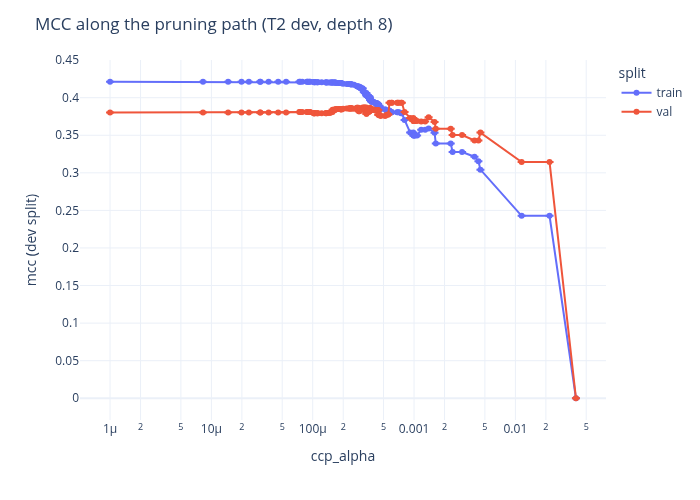

In [6]:
deep = CART(max_depth=8, **BASE).fit(dev.X_fit, dev.y_fit)
rows = []
for a in np.unique(deep.cost_complexity_path()[0]):
    p = deep.pruned(a)
    for name, X, y in (("train", dev.X_fit, dev.y_fit), ("val", dev.X_val, dev.y_val)):
        # alpha 0 (the unpruned tree) is drawn at 1e-6, so it fits on the log axis
        rows.append({"ccp_alpha": max(a, 1e-6), "split": name, "mcc": matthews_corrcoef(y, p.predict(X)), "leaves": p.n_leaves_})
alpha_df = pd.DataFrame(rows)
print("chosen alpha:", tune.choose_alpha(deep, dev))
plots.save(
    plots.validation_curve(alpha_df, "ccp_alpha", log_x=True)
    .update_layout(title="MCC along the pruning path (T2 dev, depth 8)")
    .update_yaxes(title_text="mcc (dev split)"),
    "tree_valcurve_alpha_T2",
)

## 3. Tuning on the dev split

The full grid (`max_depth` x `min_samples_leaf` x criterion x class weight = 84 points) on the dev split, as in project 1. For each point: fit, prune on validation, tune the threshold on validation. The CV below repeats this inside every fold, so this table only shows how flat the grid is.

**Limitation.** `max_depth` stops at 12. Deeper unpruned trees overfit (section 2: the train MCC keeps rising while validation stays flat), and a grid up to depth 32 did not finish within 15 hours on the pool. On T1, 12 is chosen in 3 of 5 folds, so the edge of the grid can still bind there.

In [7]:
best_dev, grid_dev = tune.grid_search(dev)
print(best_dev)
display(
    Markdown("**Grid search on the dev split** (T2): the 10 best grid points by validation MCC"),
    grid_dev.sort_values("val_mcc", ascending=False).head(10).round(4),
)

Choice(params={'max_depth': 6, 'min_samples_leaf': 10, 'criterion': 'gini', 'class_weight': None}, alpha=0.00033676605267736817, threshold=0.37037037037037035, val_mcc=0.41316107392362783, thresholds=None)


**Grid search on the dev split** (T2): the 10 best grid points by validation MCC

,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,val_mcc,depth,n_leaves
40,6,10,gini,NaN,0.0003,0.3704,0.4132,6,33
44,6,20,gini,NaN,0.0003,0.3704,0.4124,6,31
36,6,5,gini,NaN,0.0003,0.2851,0.4117,6,36
38,6,5,entropy,NaN,0.0006,0.2832,0.4096,6,40
46,6,20,entropy,NaN,0.0006,0.2832,0.4096,6,38
78,12,10,entropy,NaN,0.0005,0.3875,0.4086,12,77
42,6,10,entropy,NaN,0.0002,0.3077,0.4085,6,57
74,12,5,entropy,NaN,0.0005,0.3875,0.4077,12,83
62,10,5,entropy,NaN,0.0006,0.3400,0.4053,10,65
24,5,5,gini,NaN,0.0003,0.3704,0.4051,5,24


## 4. Cross-validation

Each fold: grid search on the validation tail, then one prediction of the test fold. Hyperparameters and the pruning alpha are chosen on the whole validation tail. The decision threshold is tuned on the whole validation tail too: one **pooled** threshold, so the pool is treated as one, more diverse repository. A variant tunes one threshold **per source** on each source's validation rows (a source with fewer than 10 validation failures keeps the pooled one). It evens out the flag rate across sources, and so throws away the between-source differences that the pooled ranking uses; it is kept as a comparison row.

Methods:

- `cart`: CART with the pooled threshold; `cart_source_thr`: the same trees with per-source thresholds.
- `sklearn`: sklearn's tree with CART's choice of each fold (params, alpha, pooled threshold); it shows how much the from-scratch implementation itself changes the result.
- `parrot`, `majority`: the history baselines. On T2 Parrot predicts all-pass, since every T2 run's previous run of its lineage passed.
- `source_rate`: knows only the source. P(fail) is the source's failure rate on the fit rows, with one threshold. A model close to it mostly tells the sources apart.

In [8]:
def sklearn_ref(choices: list[tune.Choice]):
    """sklearn tree with CART's choice per fold; run_cv visits the folds in order."""
    it = iter(choices)

    def fit_predict(split):
        c = next(it)
        m = DecisionTreeClassifier(**c.params, ccp_alpha=c.alpha, random_state=0).fit(split.X_fit, split.y_fit)
        return m.predict_proba(split.X_test)[:, 1] > c.threshold

    return fit_predict


results, payloads = {}, {}
for t in TARGETS:
    print(f"Target: {t}")
    ds, f = data[t], feats[t]
    cart, payloads[t] = run_cv(ds, f, tune.fit_predict, "cart")
    choices = [payloads[t][k]["choice"] for k in sorted(payloads[t])]
    results[t] = pd.concat(
        [
            cart,
            run_cv(ds, f, sklearn_ref(choices), "sklearn")[0],
            run_cv(ds, f, parrot, "parrot")[0],
            run_cv(ds, f, majority, "majority")[0],
            run_cv(ds, f, tune.source_rate, "source_rate")[0],
        ],
        ignore_index=True,
    )

Output()

[11/13/26 10:10:04] INFO     cart fold 1/5: fit 31667, val 7916, test 15833 (2190 failures)

Target: T2


[11/13/26 10:12:59] INFO     cart fold 2/5: fit 44333, val 11083, test 15833 (2310 failures)

[11/13/26 10:17:16] INFO     cart fold 3/5: fit 57000, val 14249, test 15833 (2393 failures)

[11/13/26 10:21:23] INFO     cart fold 4/5: fit 69666, val 17416, test 15833 (2256 failures)

... (52 outputs left out)

                    INFO     source_rate fold 2/5: fit 56201, val 14050, test 20071 (4599 failures)

                    INFO     source_rate fold 3/5: fit 72258, val 18064, test 20071 (4401 failures)

                    INFO     source_rate fold 4/5: fit 88315, val 22078, test 20071 (3968 failures)

                    INFO     source_rate fold 5/5: fit 104372, val 26092, test 20071 (4512 failures)

Choice per fold, with the validation rows and failures it was tuned on, the validation MCC it was chosen on next to the test MCC.

In [9]:
test_mcc = {t: results[t].query("method == 'cart' and source == 'all'").set_index("fold")["mcc"] for t in TARGETS}
display(
    Markdown("**CART choice per fold**: grid parameters, pruning alpha, pooled and per-source (variant) thresholds, validation rows and failures, tree size, the validation MCC it "
             "was chosen on, and the pooled test MCC"),
    pd.DataFrame(
        [
            {
                "target": t,
                "fold": k,
                **p["choice"].params,
                "alpha": p["choice"].alpha,
                "threshold": p["choice"].threshold,
                "val_rows": len(splits[t][k].y_val),
                "val_fail": int(splits[t][k].y_val.sum()),
                "per_source_thr": ", ".join(f"{v:.2f}" for v in (p["choice"].thresholds or {}).values()),
                "depth": p["tree"].depth_,
                "leaves": p["tree"].n_leaves_,
                "val_mcc": p["choice"].val_mcc,
                "test_mcc": test_mcc[t][k],
            }
            for t in TARGETS
            for k, p in payloads[t].items()
        ]
    ).round(4),
)

**CART choice per fold**: grid parameters, pruning alpha, pooled and per-source (variant) thresholds, validation rows and failures, tree size, the validation MCC it was chosen on, and the pooled test MCC

,target,fold,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,val_rows,val_fail,per_source_thr,depth,leaves,val_mcc,test_mcc
0,T2,0,10,20,entropy,balanced,0.0006,0.5870,7916,1297,"0.55, 0.69, 0.48, 0.59, 0.71, 0.60, 0.58, 0.55...",10,85,0.3149,0.2472
1,T2,1,10,5,entropy,balanced,0.0004,0.5000,11083,1496,"0.79, 0.50, 0.74, 0.15, 0.75, 0.17, 0.75, 0.50...",10,94,0.2891,0.2640
2,T2,2,6,5,entropy,balanced,0.0014,0.5000,14249,2112,"0.60, 0.71, 0.50, 0.50, 0.50, 0.50, 0.38, 0.60...",6,22,0.2688,0.2698
3,T2,3,8,5,entropy,balanced,0.0010,0.5282,17416,2569,"0.36, 0.65, 0.50, 0.50, 0.62, 0.05, 0.72, 0.52...",7,26,0.2684,0.1514
4,T2,4,10,5,entropy,balanced,0.0002,0.5699,20583,2895,"0.64, 0.69, 0.57, 0.27, 0.69, 0.16, 0.77, 0.63...",10,158,0.2068,0.1830
5,T1,0,10,20,gini,NaN,0.0001,0.4780,10036,2299,"0.22, 0.50, 0.44, 0.22, 0.48, 0.30, 0.19, 0.51...",10,102,0.4187,0.3937
6,T1,1,10,20,gini,balanced,0.0002,0.5987,14050,2895,"0.66, 0.67, 0.54, 0.40, 0.54, 0.72, 0.30, 0.89...",10,105,0.4024,0.4214
7,T1,2,12,20,entropy,NaN,0.0002,0.3938,18064,4194,"0.29, 0.40, 0.39, 0.39, 0.29, 0.65, 0.39, 0.66...",12,153,0.4347,0.3720
8,T1,3,12,20,gini,NaN,0.0001,0.3021,22078,4903,"0.46, 0.33, 0.53, 0.28, 0.30, 0.28, 0.42, 0.53...",12,153,0.3879,0.3326
9,T1,4,12,20,entropy,NaN,0.0001,0.3514,26092,5202,"0.26, 0.35, 0.35, 0.33, 0.50, 0.43, 0.31, 0.89...",12,335,0.3507,0.3517


Mean +/- std over the 5 test folds (sample std, ddof=1), first on the pooled test rows, then per source on each source's own test rows. A source with few failures in a fold gives a noisy score: the last table counts the failures per fold and source. In the box plots (pooled) the dashed line is the mean and the diamond spans mean +/- 1 std. The line chart shows each fold separately: a fold that is hard for every method is a property of that period, not of the model.

**CV results, pooled** (T2, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.223 +/- 0.053,0.357 +/- 0.038,0.270 +/- 0.029,0.536 +/- 0.104,0.718 +/- 0.036,70.733 +/- 5.791,53.607 +/- 10.410
cart_source_thr,0.161 +/- 0.049,0.313 +/- 0.030,0.241 +/- 0.044,0.471 +/- 0.081,0.692 +/- 0.074,70.001 +/- 9.285,47.140 +/- 8.058
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.853 +/- 0.007,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.853 +/- 0.007,100.000 +/- 0.000,0.000 +/- 0.000
sklearn,0.223 +/- 0.053,0.357 +/- 0.038,0.268 +/- 0.028,0.542 +/- 0.100,0.715 +/- 0.036,70.223 +/- 5.566,54.186 +/- 9.993
source_rate,0.185 +/- 0.021,0.310 +/- 0.011,0.187 +/- 0.007,0.916 +/- 0.085,0.404 +/- 0.052,28.146 +/- 7.767,91.574 +/- 8.517


**CV results per source** (T2, mean +/- std over the 5 test folds)

mcc  \
source                            method                             
Homebrew__brew__9591              cart             0.193 +/- 0.062   
                                  cart_source_thr  0.177 +/- 0.089   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.000 +/- 0.000   
                                  sklearn          0.193 +/- 0.062   
...                                                            ...   
windmill-labs__windmill__45664283 cart_source_thr  0.054 +/- 0.052   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.000 +/- 0.000   
                                  sklearn          0.019 +/- 0.049   
                                  source_rate      0.000 +/- 0.000   

                                                            recall  \
source                            method                             
Homebrew__brew__9591              cart             0.377 +/- 0.133   
                                  cart_source_thr  0.355 +/- 0.268   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.000 +/- 0.000   
                                  sklearn          0.377 +/- 0.133   
...                                                            ...   
windmill-labs__windmill__45664283 cart_source_thr  0.237 +/- 0.218   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.000 +/- 0.000   
                                  sklearn          0.042 +/- 0.093   
                                  source_rate      0.000 +/- 0.000   

                                                         precision  
source                            method                            
Homebrew__brew__9591              cart             0.245 +/- 0.093  
                                  cart_source_thr  0.254 +/- 0.088  
                                  majority         0.000 +/- 0.000  
                                  parrot           0.000 +/- 0.000  
                                  sklearn          0.244 +/- 0.093  
...                                                            ...  
windmill-labs__windmill__45664283 cart_source_thr  0.037 +/- 0.028  
                                  majority         0.000 +/- 0.000  
                                  parrot           0.000 +/- 0.000  
                                  sklearn          0.015 +/- 0.033  
                                  source_rate      0.000 +/- 0.000  

[78 rows x 3 columns]

**Failures per test fold and source** (T2)

fold,0,1,2,3,4
source,,,,,
Homebrew__brew__9591,111,135,90,53,37
all,2190,2310,2393,2256,2463
astral-sh__ruff__32130301,303,283,209,207,194
astral-sh__uv__82881044,211,191,162,292,267
github__gh-aw__180858647,23,51,19,22,42
n8n-io__n8n__33322401,884,993,1156,964,1149
n8n-io__n8n__33323319@master,74,98,94,104,121
nushell__nushell__7519865,69,40,34,22,21
servo__servo__3876879,376,362,431,368,413


[11/13/26 11:14:50] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_box_T2.*

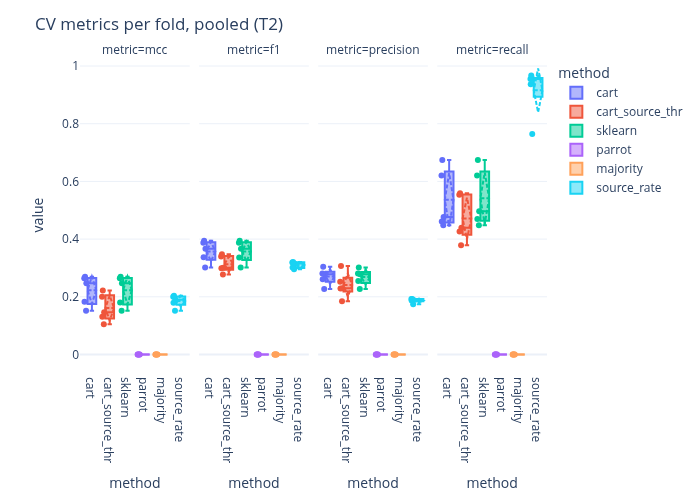

[11/13/26 11:14:55] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_folds_T2.*

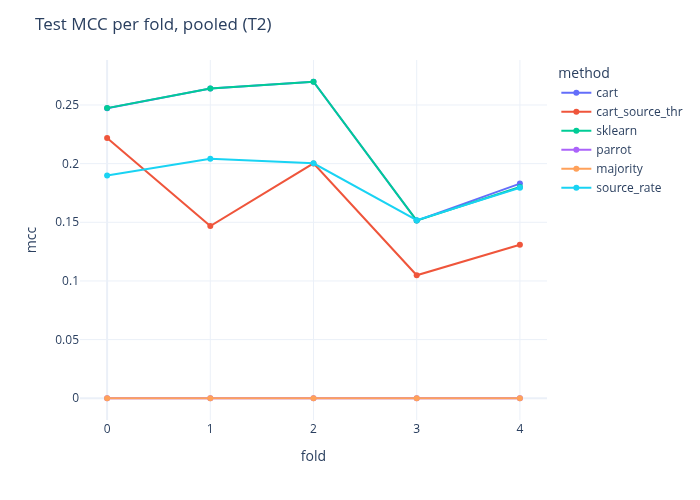

**CV results, pooled** (T1, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.374 +/- 0.035,0.502 +/- 0.036,0.531 +/- 0.050,0.482 +/- 0.067,0.793 +/- 0.012,79.999 +/- 3.841,48.170 +/- 6.710
cart_source_thr,0.354 +/- 0.038,0.478 +/- 0.049,0.530 +/- 0.033,0.441 +/- 0.080,0.793 +/- 0.008,81.762 +/- 3.937,44.060 +/- 7.973
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.782 +/- 0.012,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.353 +/- 0.031,0.483 +/- 0.031,0.520 +/- 0.033,0.451 +/- 0.029,0.790 +/- 0.007,81.048 +/- 1.078,45.135 +/- 2.866
sklearn,0.374 +/- 0.035,0.502 +/- 0.036,0.530 +/- 0.050,0.482 +/- 0.067,0.793 +/- 0.012,79.983 +/- 3.870,48.183 +/- 6.737
source_rate,0.191 +/- 0.037,0.412 +/- 0.028,0.273 +/- 0.025,0.850 +/- 0.072,0.469 +/- 0.064,31.497 +/- 9.411,85.023 +/- 7.197


**CV results per source** (T1, mean +/- std over the 5 test folds)

mcc  \
source                            method                             
Homebrew__brew__9591              cart             0.293 +/- 0.114   
                                  cart_source_thr  0.288 +/- 0.086   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.305 +/- 0.076   
                                  sklearn          0.293 +/- 0.114   
...                                                            ...   
windmill-labs__windmill__45664283 cart_source_thr  0.602 +/- 0.088   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.666 +/- 0.053   
                                  sklearn          0.617 +/- 0.040   
                                  source_rate      0.000 +/- 0.000   

                                                            recall  \
source                            method                             
Homebrew__brew__9591              cart             0.297 +/- 0.109   
                                  cart_source_thr  0.416 +/- 0.240   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.352 +/- 0.070   
                                  sklearn          0.297 +/- 0.109   
...                                                            ...   
windmill-labs__windmill__45664283 cart_source_thr  0.569 +/- 0.071   
                                  majority         0.000 +/- 0.000   
                                  parrot           0.648 +/- 0.049   
                                  sklearn          0.524 +/- 0.024   
                                  source_rate      0.000 +/- 0.000   

                                                         precision  
source                            method                            
Homebrew__brew__9591              cart             0.462 +/- 0.154  
                                  cart_source_thr  0.383 +/- 0.058  
                                  majority         0.000 +/- 0.000  
                                  parrot           0.428 +/- 0.068  
                                  sklearn          0.462 +/- 0.154  
...                                                            ...  
windmill-labs__windmill__45664283 cart_source_thr  0.685 +/- 0.158  
                                  majority         0.000 +/- 0.000  
                                  parrot           0.715 +/- 0.064  
                                  sklearn          0.760 +/- 0.076  
                                  source_rate      0.000 +/- 0.000  

[78 rows x 3 columns]

**Failures per test fold and source** (T1)

fold,0,1,2,3,4
source,,,,,
Homebrew__brew__9591,194,204,148,72,61
all,4414,4599,4401,3968,4512
astral-sh__ruff__32130301,578,485,359,361,316
astral-sh__uv__82881044,356,446,233,490,469
github__gh-aw__180858647,260,444,247,202,280
n8n-io__n8n__33322401,1767,1734,2063,1594,1895
n8n-io__n8n__33323319@master,152,173,109,150,300
nushell__nushell__7519865,85,94,58,29,27
servo__servo__3876879,752,613,803,562,694


[11/13/26 11:15:00] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_box_T1.*

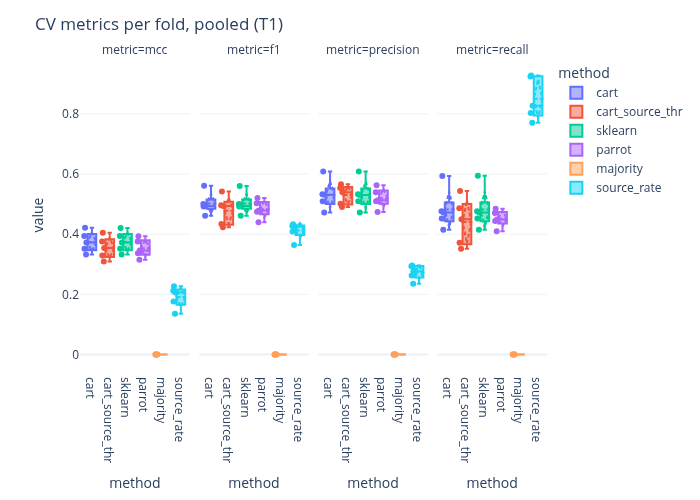

[11/13/26 11:15:05] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_folds_T1.*

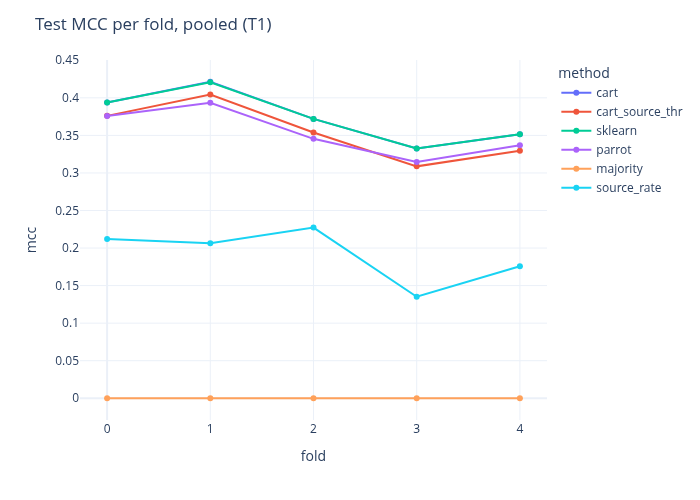

In [10]:
def mean_std(r: pd.DataFrame, metrics: list[str], by: tuple[str, ...] = ("method",)) -> pd.DataFrame:
    """'mean +/- std' over the folds (sample std, ddof=1), per `by` group."""
    g = r.groupby(list(by))[metrics]
    return g.mean().map(lambda v: f"{v:.3f}") + " +/- " + g.std().map(lambda v: f"{v:.3f}")


def pooled_rows(r: pd.DataFrame) -> pd.DataFrame:
    return r[r["source"] == "all"]


for t in TARGETS:
    r = results[t]
    display(
        Markdown(f"**CV results, pooled** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(pooled_rows(r), METRICS),
        Markdown(f"**CV results per source** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(r[r["source"] != "all"], ["mcc", "recall", "precision"], by=("source", "method")),
        Markdown(f"**Failures per test fold and source** ({t})"),
        r.query("method == 'cart'").pivot(index="source", columns="fold", values="n_fail"),
    )
    long = pooled_rows(r).melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold, pooled ({t})"), f"tree_cv_box_{t}"))
    display(plots.save(
        px.line(pooled_rows(r), x="fold", y="mcc", color="method", markers=True)
        .update_layout(title=f"Test MCC per fold, pooled ({t})"),
        f"tree_cv_folds_{t}",
    ))

## 5. Statistical tests

Paired two-sided Wilcoxon signed-rank test and the Vargha-Delaney A12 (P(first method > second); 0.5 = no difference) on the test MCC. With only the 5 pooled folds, the smallest reachable p is 0.0625, so no comparison could reach 0.05. The pairs are therefore the **(fold, source) cells**: the MCC of one source's test rows in one fold. Cells with fewer than 10 test failures are left out (`MIN_TEST_FAILURES`). Cells of one fold share a model and a time window, so they are not independent, and the p-values are optimistic. `min_p` is the smallest p reachable with `n` non-zero pairs.

**Constant baselines.** `source_rate` and `majority` predict one class per source, so their MCC is 0 in every cell by construction, and a cell test against them only asks whether the model beats 0. They are compared on the pooled rows only: the mean difference and the folds won, no p-value. On T2, Parrot is constant too (every T2 run follows a pass), so it is tested on T1 only.

The per-fold pooled table follows as the plain view.

In [11]:
CELL_VS = {"T2": (), "T1": ("parrot",)}  # Parrot is constant on T2
POOLED_VS = ("source_rate", "majority")  # constant per source: 0 MCC in every cell


def compare_rows(r: pd.DataFrame, first: str, others: tuple[str, ...], label: str) -> list[dict]:
    cells = st.per_cell(r, "mcc")
    return [
        {label: f"{first} vs {o}", "cells": len(cells[[first, o]].dropna()), **st.compare(cells, first, o)}
        for o in others
        if o in cells
    ]


def show_cells(rows: list[dict]) -> pd.DataFrame:
    """Rounded comparison table; `min_p` in scientific notation, since it is often far below 1e-4."""
    return pd.DataFrame(rows).round(4).assign(min_p=lambda d: d["min_p"].map(lambda v: f"{v:.1e}"))


def pooled_vs(r: pd.DataFrame, first: str, others: tuple[str, ...]) -> pd.DataFrame:
    """Mean pooled test MCC of `first` and each other method, and the folds `first` wins."""
    f = st.per_fold(r, "mcc")
    return pd.DataFrame(
        [
            {
                "comparison": f"{first} vs {o}",
                first: f[first].mean(),
                "other": f[o].mean(),
                "mean_diff": (f[first] - f[o]).mean(),
                "folds_won": f"{int((f[first] > f[o]).sum())}/{len(f)}",
            }
            for o in others
            if o in f
        ]
    ).round(4)


for t in TARGETS:
    display(
        Markdown(f"**CART vs. the other methods** ({t}): paired Wilcoxon and A12 on the (fold, source) MCC cells"),
        show_cells(compare_rows(results[t], "cart", ("cart_source_thr", *CELL_VS[t], "sklearn"), "test")),
        Markdown(f"**CART vs. the constant baselines, pooled rows** ({t}): mean test MCC over the 5 folds and folds won"),
        pooled_vs(results[t], "cart", POOLED_VS),
        Markdown(f"**Test MCC per fold and method**, pooled ({t})"),
        st.per_fold(results[t], "mcc").round(3),
    )


**CART vs. the other methods** (T2): paired Wilcoxon and A12 on the (fold, source) MCC cells

,test,cells,mean_diff,p,n,min_p,flag,A12
0,cart vs cart_source_thr,62,-0.0031,0.4742,46,0.0e+00,zero_diffs_dropped,0.4788
1,cart vs sklearn,62,-0.0003,0.7989,10,2.0e-03,zero_diffs_dropped,0.4979


**CART vs. the constant baselines, pooled rows** (T2): mean test MCC over the 5 folds and folds won

,comparison,cart,other,mean_diff,folds_won
0,cart vs source_rate,0.2231,0.1851,0.0380,4/5
1,cart vs majority,0.2231,0.0000,0.2231,5/5


**Test MCC per fold and method**, pooled (T2)

method,cart,cart_source_thr,majority,parrot,sklearn,source_rate
fold,,,,,,
0,0.247,0.222,0.0,0.0,0.247,0.190
1,0.264,0.147,0.0,0.0,0.264,0.204
2,0.270,0.200,0.0,0.0,0.270,0.200
3,0.151,0.105,0.0,0.0,0.151,0.152
4,0.183,0.131,0.0,0.0,0.180,0.179


... (2 outputs left out)

**CART vs. the constant baselines, pooled rows** (T1): mean test MCC over the 5 folds and folds won

,comparison,cart,other,mean_diff,folds_won
0,cart vs source_rate,0.3743,0.1914,0.1829,5/5
1,cart vs majority,0.3743,0.0000,0.3743,5/5


**Test MCC per fold and method**, pooled (T1)

method,cart,cart_source_thr,majority,parrot,sklearn,source_rate
fold,,,,,,
0,0.394,0.376,0.0,0.376,0.394,0.212
1,0.421,0.404,0.0,0.393,0.421,0.206
2,0.372,0.354,0.0,0.345,0.372,0.227
3,0.333,0.309,0.0,0.315,0.333,0.135
4,0.352,0.329,0.0,0.337,0.352,0.176


## 6. What the tree uses

**Repository proxy.** Each source has its own failure rate and its own scale of loads, churn and durations, so a tree can first recognise the source and then predict its rate. Two checks: `cart` against `source_rate` on the pooled rows in section 5 (how much of the pooled MCC knowing the source alone gives), and the per-source MCC of section 4 (a tree that only recognised sources would score about 0 within each source). The top splits of the last fold's tree follow below.

Impurity-decrease importance of each fold's final (pruned) tree. The table gives the mean and std over the folds; the plot shows one point per fold and the dashed line is the mean. No +/- std band here: importances are bounded at 0 and skewed (a feature can be large in one fold and 0 in the others), so mean - std would fall below 0.

**Impurity-decrease importance per fold** (T2, final tree of each fold), with mean and std

,0,1,2,3,4,mean,std
event_push,0.101,0.285,0.375,0.379,0.309,0.290,0.113
author_prior_fail_rate,0.129,0.165,0.161,0.144,0.136,0.147,0.016
file_fail_prob_max,0.068,0.093,0.085,0.107,0.088,0.088,0.014
fail_rate_last_50,0.051,0.087,0.096,0.098,0.085,0.083,0.019
fail_rate_24h,0.274,0.018,0.027,0.035,0.023,0.075,0.111
event_pull_request,0.102,0.062,0.074,0.075,0.048,0.072,0.020
lineage_prior_runs,0.033,0.048,0.053,0.054,0.048,0.047,0.008
flaky_rate_7d,0.039,0.042,0.052,0.050,0.044,0.046,0.005
churn,0.041,0.038,0.036,0.027,0.033,0.035,0.005
fail_rate_7d,0.013,0.046,0.008,0.007,0.024,0.020,0.016


[11/13/26 11:15:10] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_importance_T2.*

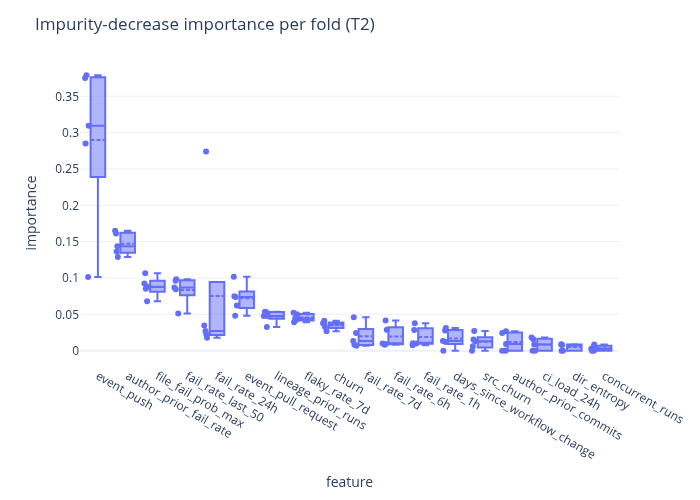

**Impurity-decrease importance per fold** (T1, final tree of each fold), with mean and std

,0,1,2,3,4,mean,std
fail_streak,0.095,0.047,0.460,0.544,0.460,0.321,0.232
fail_rate_last_5,0.456,0.458,0.019,0.020,0.015,0.194,0.240
author_prior_fail_rate,0.099,0.095,0.091,0.120,0.167,0.114,0.031
fail_rate_12h,0.107,0.149,0.125,0.023,0.031,0.087,0.057
event_pull_request,0.065,0.084,0.096,0.094,0.093,0.086,0.013
file_fail_prob_max,0.030,0.036,0.046,0.066,0.046,0.045,0.014
additions,0.020,0.012,0.019,0.018,0.026,0.019,0.005
flaky_rate_7d,0.011,0.022,0.022,0.013,0.015,0.016,0.005
runs_since_last_fail,0.018,0.018,0.016,0.014,0.011,0.016,0.003
file_prior_changes,0.019,0.004,0.015,0.014,0.022,0.015,0.007


[11/13/26 11:15:15] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_importance_T1.*

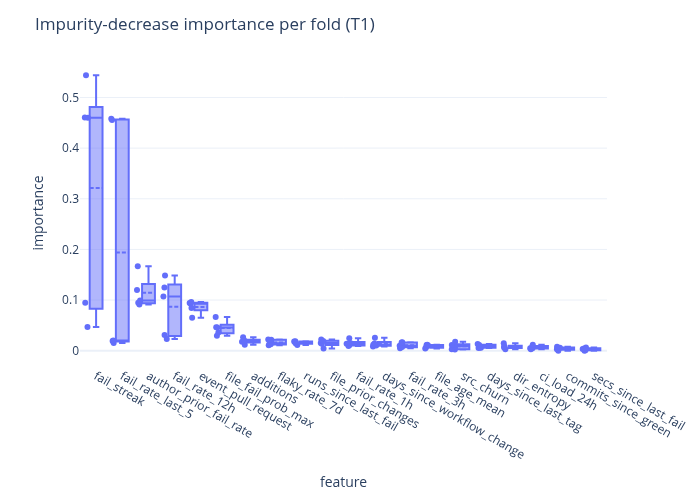

In [12]:
for t in TARGETS:
    imp = pd.DataFrame({k: p["tree"].feature_importances_ for k, p in payloads[t].items()}, index=feats[t])
    imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
    display(
        Markdown(f"**Impurity-decrease importance per fold** ({t}, final tree of each fold), with mean and std"),
        imp.assign(mean=imp.mean(axis=1), std=imp.std(axis=1)).round(3),
    )
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="fold", value_name="importance")
    display(plots.save(
        px.box(long, x="feature", y="importance", points="all", hover_data=["fold"])
        .update_traces(boxmean=True)
        .update_layout(title=f"Impurity-decrease importance per fold ({t})"),
        f"tree_importance_{t}",
    ))

**Event mix per source.** `event_push` leads the T2 tree. The event mix differs per repository, so the feature may partly stand for the source. The table gives each source's share of runs per event, next to its failure rate; it is a display, not a test.

In [13]:
for t in TARGETS:
    ds_t = data[t]
    mix = ds_t.X.filter(like="event_").groupby(ds_t.source).mean()
    display(
        Markdown(f"**Share of runs per event and source** ({t}), with the source's failure rate"),
        mix.assign(fail_rate=ds_t.y.groupby(ds_t.source).mean()).round(3),
    )


**Share of runs per event and source** (T2), with the source's failure rate

,event_merge_group,event_pull_request,event_push,fail_rate
source,,,,
Homebrew__brew__9591,0.287,0.493,0.220,0.115
astral-sh__ruff__32130301,0.000,0.818,0.182,0.140
astral-sh__uv__82881044,0.000,0.816,0.184,0.238
github__gh-aw__180858647,0.000,0.173,0.827,0.165
n8n-io__n8n__33322401,0.288,0.712,0.000,0.245
n8n-io__n8n__33323319@master,0.000,0.000,1.000,0.165
nushell__nushell__7519865,0.000,0.622,0.378,0.156
servo__servo__3876879,0.295,0.542,0.163,0.216
sharkdp__fd__11202521,0.000,0.772,0.228,0.178


**Share of runs per event and source** (T1), with the source's failure rate

,event_merge_group,event_pull_request,event_push,fail_rate
source,,,,
Homebrew__brew__9591,0.260,0.543,0.197,0.166
astral-sh__ruff__32130301,0.000,0.839,0.161,0.183
astral-sh__uv__82881044,0.000,0.791,0.209,0.300
github__gh-aw__180858647,0.000,0.115,0.885,0.482
n8n-io__n8n__33322401,0.256,0.744,0.000,0.326
n8n-io__n8n__33323319@master,0.000,0.000,1.000,0.261
nushell__nushell__7519865,0.000,0.658,0.342,0.196
servo__servo__3876879,0.289,0.554,0.157,0.275
sharkdp__fd__11202521,0.000,0.781,0.219,0.206


The tree of the last fold (largest train set), top 3 levels. Box width = runs reaching the node, colour = P(fail).

|--- event_push <= 0.5
|   |--- author_prior_fail_rate <= 0.413881
|   |   |--- event_pull_request <= 0.5
|   |   |   |--- ...
|   |   |--- event_pull_request > 0.5
|   |   |   |--- ...
|   |--- author_prior_fail_rate > 0.413881
|   |   |--- author_prior_fail_rate <= 0.611458
|   |   |   |--- ...
|   |   |--- author_prior_fail_rate > 0.611458
|   |   |   |--- ...
|--- event_push > 0.5
|   |--- fail_rate_last_50 <= 0.0779352
|   |   |--- file_fail_prob_max <= 0.155509
|   |   |   |--- ...
|   |   |--- file_fail_prob_max > 0.155509
|   |   |   |--- ...
|   |--- fail_rate_last_50 > 0.0779352
|   |   |--- fail_rate_24h <= 0.177317
|   |   |   |--- ...
|   |   |--- fail_rate_24h > 0.177317
|   |   |   |--- ...


[11/13/26 11:15:19] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_icicle_T2.*

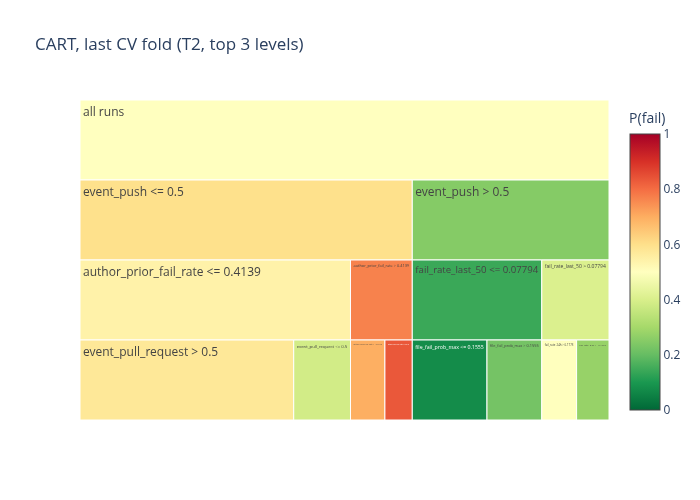

In [14]:
last = payloads["T2"][max(payloads["T2"])]["tree"]
print(last.export_text(max_depth=3))
plots.save(
    plots.tree_icicle(last.tree_, last.feature_names_, max_depth=3).update_layout(title="CART, last CV fold (T2, top 3 levels)"),
    "tree_icicle_T2",
)

## 7. Errors and the cost trade-off

Confusion matrix of CART, summed over the 5 test folds: pooled, then per source.

[11/13/26 11:15:23] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_confusion_T2.*

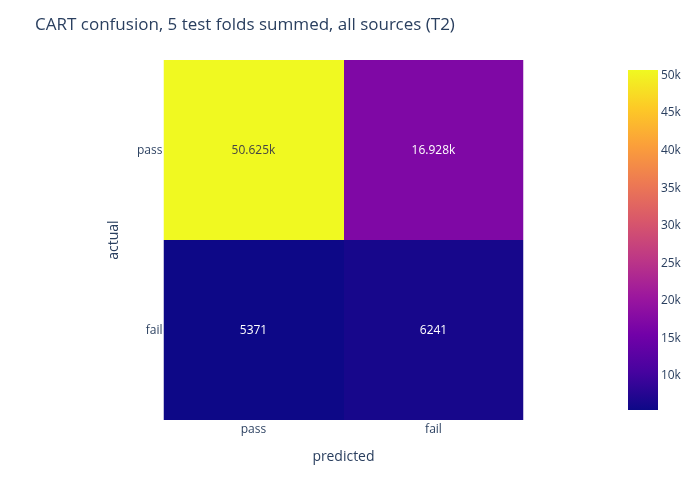

**CART confusion per source** (T2, summed over the 5 test folds)

,tn,fp,fn,tp
source,,,,
Homebrew__brew__9591,3278,627,256,170
astral-sh__ruff__32130301,6088,1704,707,489
astral-sh__uv__82881044,2522,1439,561,562
github__gh-aw__180858647,1159,25,154,3
n8n-io__n8n__33322401,10709,9335,1609,3537
n8n-io__n8n__33323319@master,3384,112,463,28
nushell__nushell__7519865,819,277,109,77
servo__servo__3876879,3770,2727,823,1127
sharkdp__fd__11202521,185,28,29,17


[11/13/26 11:15:28] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_confusion_T1.*

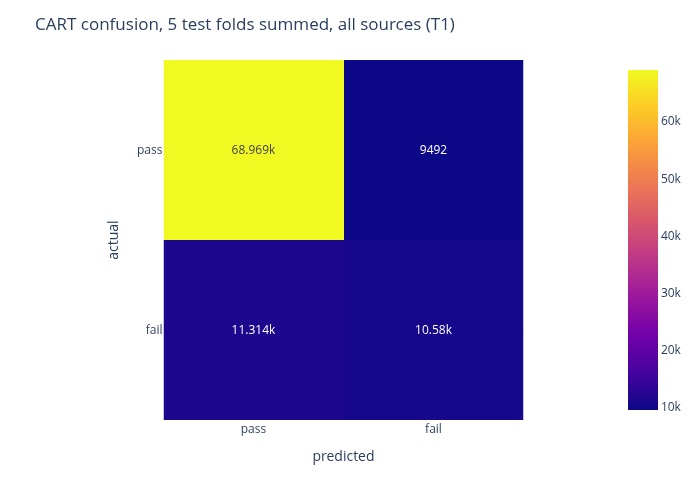

**CART confusion per source** (T1, summed over the 5 test folds)

,tn,fp,fn,tp
source,,,,
Homebrew__brew__9591,4056,245,453,226
astral-sh__ruff__32130301,8451,717,1413,686
astral-sh__uv__82881044,3960,876,1122,872
github__gh-aw__180858647,1222,190,182,1251
n8n-io__n8n__33322401,19091,5275,4239,4814
n8n-io__n8n__33323319@master,3854,234,584,300
nushell__nushell__7519865,1128,153,180,113
servo__servo__3876879,7053,1222,2094,1330
sharkdp__fd__11202521,222,29,46,16


In [15]:
def pooled(t: str, method: str, source: str = "all") -> pd.Series:
    r = results[t]
    return r[(r["method"] == method) & (r["source"] == source)][["tn", "fp", "fn", "tp"]].sum()


for t in TARGETS:
    c = pooled(t, "cart")
    display(plots.save(
        plots.confusion(np.array([[c.tn, c.fp], [c.fn, c.tp]]))
        .update_layout(title=f"CART confusion, 5 test folds summed, all sources ({t})"),
        f"tree_confusion_{t}",
    ))
    per_source = results[t].query("method == 'cart' and source != 'all'").groupby("source")[["tn", "fp", "fn", "tp"]].sum()
    display(Markdown(f"**CART confusion per source** ({t}, summed over the 5 test folds)"), per_source)

**Trade-off.** Each fold's tree scores its test fold; the probabilities are pooled and one threshold is swept over all of them. A higher threshold skips more builds (`% builds saved`) and catches fewer failures. The star is CART with its tuned per-fold thresholds; the diamond is Parrot. The dotted line is a random guess that flags a share q of the builds and so catches a share q of the failures (caught = 100 - saved): the distance above it is what the model adds.

**Pooled, not averaged.** Every point here counts all test runs together, so folds with more failures weigh more, and it differs from the fold means above. A single global threshold read off this curve uses the test labels, so it is a diagnosis of the threshold choice, not a result.

[11/13/26 11:15:32] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_tradeoff_T2.*

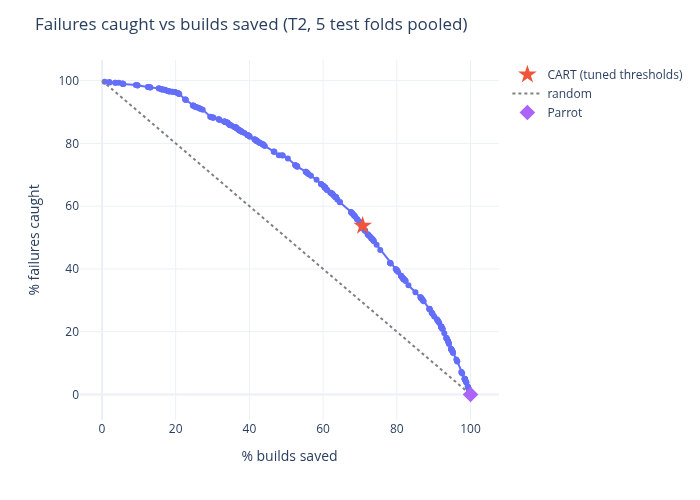

[11/13/26 11:15:37] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_tradeoff_T1.*

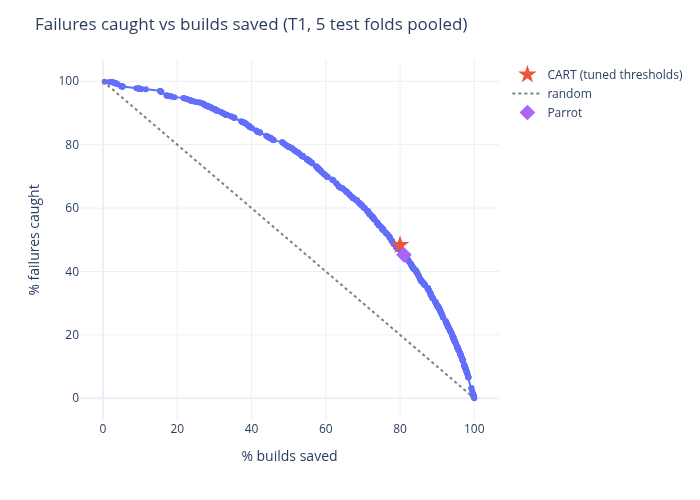

In [16]:
def point(c: pd.Series) -> tuple[float, float]:
    return 100 * (c.tn + c.fn) / c.sum(), 100 * c.tp / (c.tp + c.fn)


for t in TARGETS:
    proba = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    curve = pd.DataFrame(
        [
            {"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)}
            for th in np.unique(np.r_[0.0, proba])
        ]
    )
    fig = plots.tradeoff(curve, point(pooled(t, "cart")), "CART (tuned thresholds)")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved ({t}, 5 test folds pooled)"), f"tree_tradeoff_{t}"))

## 8. E1 and E3

Two experiments next to the pooled model (E2, `cart` above), on T2 and on the **same test rows** as E2: the pooled folds are kept, and only the rows a model is trained on change. So every (fold, source) cell of E1 and E3 pairs with the same cell of E2.

- **E1, one tree per source**: fit and validation rows of one source only, its own feature list (`feature_selection.ipynb`, section 6.1), scored on that source's test rows. Sources without a list are skipped.
- **E3, leave one repository out**: features selected on the pool's dev rows without repository X (same selection parameters as the pooled list), trees fitted on the pool without X, scored on X's test rows. X never appears in validation, so it gets the pooled threshold. To keep the run time bounded, each fold reuses E2's grid choice of that fold; alpha and the threshold are tuned again on the validation rows without X.

CART only: the forest would multiply the run time.

In [17]:
E_T = "T2"
ds = data[E_T]
src = ds.source.to_numpy()
repo = ds.source.map(repo_of).to_numpy()
sel_meta = json.loads((fs.OUT_DIR / f"selected_features_{E_T}_{DATASET}.json").read_text())["meta"]
e1_feats = {s: load_features(E_T, s) for s in SOURCES if (fs.OUT_DIR / f"selected_features_{E_T}_{s}.json").exists()}
e2_choices = [payloads[E_T][k]["choice"] for k in sorted(payloads[E_T])]


def with_e2_params(choices: list[tune.Choice]):
    """tune.fit_predict with E2's grid choice of each fold; run_cv visits the folds in order."""
    it = iter(choices)
    return lambda split: tune.fit_predict(split, next(it).params)


e_parts = []
for s, f in e1_feats.items():
    print(f"E1: {s}")
    r, _ = run_cv(ds, f, tune.fit_predict, "cart_e1", train=src == s, test=src == s)
    e_parts.append(r[r["source"] == s])
for x in sorted({repo_of(s) for s in e1_feats}):
    print(f"E3: without {x}")
    out = repo != x
    sel_x = fs.select_features(
        subset(ds, out, dataset=f"{DATASET}-without-{x}"), **sel_meta["params"], exclude=tuple(sel_meta["excluded"])
    )
    r, _ = run_cv(ds, sel_x.features, with_e2_params(e2_choices), "cart_e3", train=out, test=~out)
    e_parts.append(r[(r["source"] != "all") & (r["method"] == "cart_e3")])
e_results = pd.concat(e_parts, ignore_index=True)

Output()

[11/13/26 11:15:39] INFO     cart_e1 fold 1/5: fit 8205, val 2053, test 4107 (884 failures)

E1: n8n-io__n8n__33322401


[11/13/26 11:16:11] INFO     cart_e1 fold 2/5: fit 11625, val 2740, test 4561 (993 failures)

[11/13/26 11:16:53] INFO     cart_e1 fold 3/5: fit 14778, val 4148, test 4695 (1156 failures)

[11/13/26 11:17:52] INFO     cart_e1 fold 4/5: fit 18470, val 5151, test 5934 (964 failures)

... (157 outputs left out)

[11/13/26 11:56:16] INFO     cart_e3 fold 2/5: fit 36408, val 8558, test 4142 (103 failures)

[11/13/26 11:56:20] INFO     cart_e3 fold 3/5: fit 46012, val 10645, test 3973 (108 failures)

[11/13/26 11:56:21] INFO     cart_e3 fold 4/5: fit 55418, val 13099, test 3499 (123 failures)

[11/13/26 11:56:22] INFO     cart_e3 fold 5/5: fit 65184, val 15667, test 3236 (119 failures)

In [18]:
ecmp = pd.concat([results[E_T].query("method == 'cart' and source != 'all'"), e_results], ignore_index=True)
display(
    Markdown(f"**E1, E2 and E3 per source** ({E_T}, test MCC mean +/- std over the 5 folds; `cart` = E2, the pooled model)"),
    mean_std(ecmp, ["mcc"], by=("source", "method")).unstack("method"),
)
rows = [
    {"source": s, "comparison": f"{a} vs {b}", **st.compare(st.per_cell(ecmp[ecmp.source == s], "mcc"), a, b)}
    for s in sorted(ecmp.source.unique())
    for a, b in (("cart", "cart_e1"), ("cart_e3", "cart_e1"))
    if {a, b} <= set(ecmp.query("source == @s").method)
]
display(
    Markdown(f"**E2 and E3 against E1, per source** ({E_T}): 5 folds per source, so only the mean difference and A12 "
             "are informative (smallest p = 0.0625); cells with < 10 test failures are left out"),
    pd.DataFrame(rows)[["source", "comparison", "mean_diff", "n", "A12"]].round(4),
    Markdown(f"**E2 and E3 against E1, all sources** ({E_T}): paired Wilcoxon and A12 on the (fold, source) MCC cells"),
    show_cells(compare_rows(ecmp, "cart", ("cart_e1", "cart_e3"), "test") + compare_rows(ecmp, "cart_e3", ("cart_e1",), "test")),
)

**E1, E2 and E3 per source** (T2, test MCC mean +/- std over the 5 folds; `cart` = E2, the pooled model)

mcc                   \
method                                          cart          cart_e1   
source                                                                  
Homebrew__brew__9591                 0.193 +/- 0.062  0.135 +/- 0.043   
astral-sh__ruff__32130301            0.163 +/- 0.017  0.152 +/- 0.011   
astral-sh__uv__82881044              0.124 +/- 0.057  0.126 +/- 0.044   
github__gh-aw__180858647            -0.004 +/- 0.033  0.019 +/- 0.095   
n8n-io__n8n__33322401                0.179 +/- 0.080  0.202 +/- 0.095   
n8n-io__n8n__33323319@master         0.029 +/- 0.064  0.014 +/- 0.023   
nushell__nushell__7519865            0.110 +/- 0.085  0.168 +/- 0.120   
servo__servo__3876879                0.131 +/- 0.052  0.141 +/- 0.041   
sharkdp__fd__11202521                0.198 +/- 0.181  0.059 +/- 0.168   
sveltejs__svelte__14783              0.166 +/- 0.082  0.155 +/- 0.161   
tokio-rs__tokio__1972898             0.230 +/- 0.141  0.128 +/- 0.089   
windmill-labs__windmill__133951533   0.035 +/- 0.048  0.069 +/- 0.110   
windmill-labs__windmill__45664283    0.019 +/- 0.049  0.131 +/- 0.097   

                                                      
method                                       cart_e3  
source                                                
Homebrew__brew__9591                 0.126 +/- 0.051  
astral-sh__ruff__32130301            0.128 +/- 0.032  
astral-sh__uv__82881044              0.108 +/- 0.046  
github__gh-aw__180858647            -0.065 +/- 0.030  
n8n-io__n8n__33322401                0.026 +/- 0.021  
n8n-io__n8n__33323319@master         0.009 +/- 0.049  
nushell__nushell__7519865            0.088 +/- 0.112  
servo__servo__3876879                0.057 +/- 0.061  
sharkdp__fd__11202521                0.218 +/- 0.170  
sveltejs__svelte__14783              0.221 +/- 0.049  
tokio-rs__tokio__1972898             0.236 +/- 0.124  
windmill-labs__windmill__133951533   0.098 +/- 0.230  
windmill-labs__windmill__45664283    0.015 +/- 0.038

**E2 and E3 against E1, per source** (T2): 5 folds per source, so only the mean difference and A12 are informative (smallest p = 0.0625); cells with < 10 test failures are left out

,source,comparison,mean_diff,n,A12
0,Homebrew__brew__9591,cart vs cart_e1,0.0584,5,0.76
1,Homebrew__brew__9591,cart_e3 vs cart_e1,-0.0084,5,0.48
2,astral-sh__ruff__32130301,cart vs cart_e1,0.0114,5,0.80
3,astral-sh__ruff__32130301,cart_e3 vs cart_e1,-0.0241,5,0.24
4,astral-sh__uv__82881044,cart vs cart_e1,-0.0016,5,0.52
5,astral-sh__uv__82881044,cart_e3 vs cart_e1,-0.0177,5,0.36
6,github__gh-aw__180858647,cart vs cart_e1,-0.0228,5,0.44
7,github__gh-aw__180858647,cart_e3 vs cart_e1,-0.0844,5,0.08
8,n8n-io__n8n__33322401,cart vs cart_e1,-0.0230,5,0.40
9,n8n-io__n8n__33322401,cart_e3 vs cart_e1,-0.1763,5,0.00


**E2 and E3 against E1, all sources** (T2): paired Wilcoxon and A12 on the (fold, source) MCC cells

,test,cells,mean_diff,p,n,min_p,flag,A12
0,cart vs cart_e1,62,-0.0001,0.9637,62,0.0e+00,NaN,0.4828
1,cart vs cart_e3,62,0.0238,0.0062,58,0.0e+00,zero_diffs_dropped,0.5795
2,cart_e3 vs cart_e1,62,-0.0239,0.0094,61,0.0e+00,zero_diffs_dropped,0.4015


## 9. Random forest (bagging over CART)

A single CART is a weak learner. A random forest (Breiman, 2001; `tree/forest.py`) averages 100 of our own CART trees. Each tree is fitted on a bootstrap sample of the fit rows and draws sqrt(p) columns at every node, so the trees differ and part of their errors cancel. P(fail) is the mean of the trees' leaf shares.

**Protocol.** Same folds, features and validation tail as CART, scored pooled and per source. The trees are not pruned. The grid (`max_depth` in {8, None} x `min_samples_leaf` in {5, 20} x class weight = 8 points) and the decision threshold are chosen on validation MCC; each test fold is read once. The seed is fixed (`random_state=0`), so each fold is run once, as for CART.

**What it costs.** A forest has no single readable path, so it is not the model we explain. It shows how much accuracy the single tree gives up for its explanation.

In [19]:
rf_payloads = {}
for t in TARGETS:
    print(f"Target: {t}")
    rf, rf_payloads[t] = run_cv(data[t], feats[t], forest.fit_predict, "forest")
    # drop an earlier forest run first, so the cell can be re-run
    results[t] = pd.concat([results[t].query("method not in ('forest', 'forest_source_thr')"), rf], ignore_index=True)

Output()

[11/13/26 11:56:28] INFO     forest fold 1/5: fit 31667, val 7916, test 15833 (2190 failures)

Target: T2


[11/13/26 11:58:44] INFO     forest fold 2/5: fit 44333, val 11083, test 15833 (2310 failures)

[11/13/26 12:02:15] INFO     forest fold 3/5: fit 57000, val 14249, test 15833 (2393 failures)

[11/13/26 12:06:36] INFO     forest fold 4/5: fit 69666, val 17416, test 15833 (2256 failures)

... (4 outputs left out)

[11/13/26 12:23:44] INFO     forest fold 2/5: fit 56201, val 14050, test 20071 (4599 failures)

[11/13/26 12:29:34] INFO     forest fold 3/5: fit 72258, val 18064, test 20071 (4401 failures)

[11/13/26 12:36:12] INFO     forest fold 4/5: fit 88315, val 22078, test 20071 (3968 failures)

[11/13/26 12:45:21] INFO     forest fold 5/5: fit 104372, val 26092, test 20071 (4512 failures)

Choice per fold, with the validation rows and failures, the validation MCC it was chosen on, the test MCC, and CART's test MCC on the same fold.

In [20]:
rf_mcc = {t: results[t].query("method == 'forest' and source == 'all'").set_index("fold")["mcc"] for t in TARGETS}
display(
    Markdown("**Forest choice per fold**: grid parameters, threshold, validation rows and failures, mean tree depth, the validation MCC it was "
             "chosen on, the pooled test MCC, and CART's pooled test MCC on the same fold"),
    pd.DataFrame(
        [
            {
                "target": t,
                "fold": k,
                **p["choice"].params,
                "threshold": p["choice"].threshold,
                "val_rows": len(splits[t][k].y_val),
                "val_fail": int(splits[t][k].y_val.sum()),
                "mean_depth": np.mean([tr.depth_ for tr in p["forest"].estimators_]),
                "val_mcc": p["choice"].val_mcc,
                "test_mcc": rf_mcc[t][k],
                "cart_test_mcc": test_mcc[t][k],
            }
            for t in TARGETS
            for k, p in rf_payloads[t].items()
        ]
    ).round(4),
)

**Forest choice per fold**: grid parameters, threshold, validation rows and failures, mean tree depth, the validation MCC it was chosen on, the pooled test MCC, and CART's pooled test MCC on the same fold

,target,fold,max_depth,min_samples_leaf,class_weight,threshold,val_rows,val_fail,mean_depth,val_mcc,test_mcc,cart_test_mcc
0,T2,0,NaN,20,NaN,0.2595,7916,1297,20.65,0.3396,0.3050,0.2472
1,T2,1,NaN,20,balanced,0.5427,11083,1496,21.97,0.3070,0.2843,0.2640
2,T2,2,NaN,20,balanced,0.5062,14249,2112,23.22,0.2890,0.2804,0.2698
3,T2,3,NaN,20,NaN,0.2458,17416,2569,24.74,0.2897,0.1671,0.1514
4,T2,4,8.0,5,NaN,0.0757,20583,2895,8.00,0.2123,0.2003,0.1830
5,T1,0,NaN,20,balanced,0.5536,10036,2299,22.14,0.4570,0.4382,0.3937
6,T1,1,NaN,20,balanced,0.5133,14050,2895,23.62,0.4454,0.4597,0.4214
7,T1,2,NaN,20,balanced,0.5464,18064,4194,24.59,0.4717,0.4054,0.3720
8,T1,3,NaN,20,balanced,0.5006,22078,4903,25.63,0.4196,0.3455,0.3326
9,T1,4,NaN,20,NaN,0.4050,26092,5202,26.57,0.3761,0.3768,0.3517


Mean +/- std over the 5 test folds, pooled and per source, next to CART and the baselines (same tables and plots as section 4).

**CV results, pooled, forest vs. CART and the baselines** (T2, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.223 +/- 0.053,0.357 +/- 0.038,0.270 +/- 0.029,0.536 +/- 0.104,0.718 +/- 0.036,70.733 +/- 5.791,53.607 +/- 10.410
forest,0.247 +/- 0.060,0.368 +/- 0.048,0.300 +/- 0.075,0.562 +/- 0.237,0.700 +/- 0.185,68.009 +/- 25.553,56.193 +/- 23.673
forest_source_thr,0.191 +/- 0.034,0.317 +/- 0.023,0.298 +/- 0.048,0.353 +/- 0.073,0.776 +/- 0.045,81.934 +/- 6.394,35.306 +/- 7.288
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.853 +/- 0.007,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.853 +/- 0.007,100.000 +/- 0.000,0.000 +/- 0.000
source_rate,0.185 +/- 0.021,0.310 +/- 0.011,0.187 +/- 0.007,0.916 +/- 0.085,0.404 +/- 0.052,28.146 +/- 7.767,91.574 +/- 8.517


**CV results per source, forest vs. CART and the baselines** (T2, mean +/- std over the 5 test folds)

mcc  \
source                            method                               
Homebrew__brew__9591              cart               0.193 +/- 0.062   
                                  forest             0.197 +/- 0.082   
                                  forest_source_thr  0.181 +/- 0.070   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.000 +/- 0.000   
...                                                              ...   
windmill-labs__windmill__45664283 forest             0.068 +/- 0.153   
                                  forest_source_thr  0.129 +/- 0.120   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.000 +/- 0.000   
                                  source_rate        0.000 +/- 0.000   

                                                              recall  \
source                            method                               
Homebrew__brew__9591              cart               0.377 +/- 0.133   
                                  forest             0.374 +/- 0.290   
                                  forest_source_thr  0.319 +/- 0.195   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.000 +/- 0.000   
...                                                              ...   
windmill-labs__windmill__45664283 forest             0.059 +/- 0.133   
                                  forest_source_thr  0.422 +/- 0.340   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.000 +/- 0.000   
                                  source_rate        0.000 +/- 0.000   

                                                           precision  
source                            method                              
Homebrew__brew__9591              cart               0.245 +/- 0.093  
                                  forest             0.282 +/- 0.126  
                                  forest_source_thr  0.249 +/- 0.061  
                                  majority           0.000 +/- 0.000  
                                  parrot             0.000 +/- 0.000  
...                                                              ...  
windmill-labs__windmill__45664283 forest             0.085 +/- 0.189  
                                  forest_source_thr  0.166 +/- 0.283  
                                  majority           0.000 +/- 0.000  
                                  parrot             0.000 +/- 0.000  
                                  source_rate        0.000 +/- 0.000  

[78 rows x 3 columns]

[11/13/26 12:55:29] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_box_T2.*

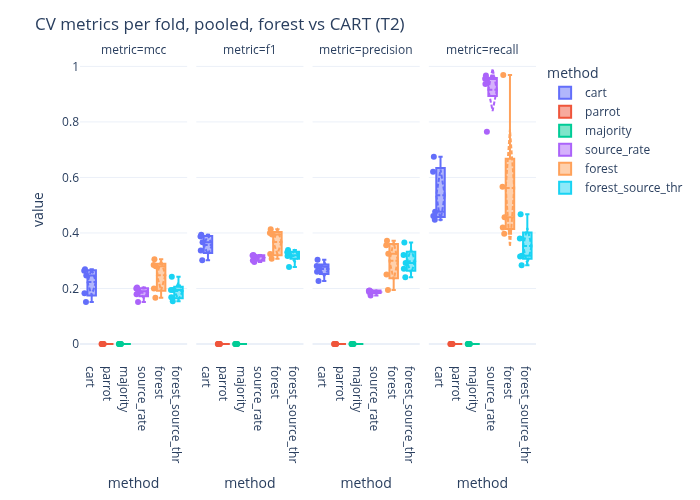

[11/13/26 12:55:34] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_folds_T2.*

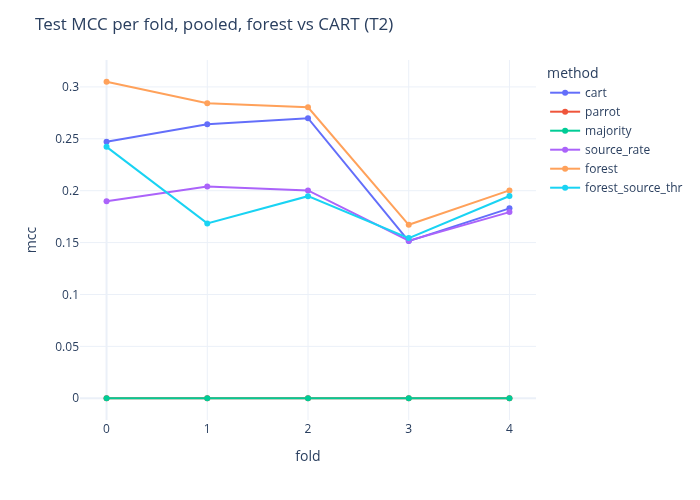

**CV results, pooled, forest vs. CART and the baselines** (T1, mean +/- std over the 5 test folds)

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
method,,,,,,,
cart,0.374 +/- 0.035,0.502 +/- 0.036,0.531 +/- 0.050,0.482 +/- 0.067,0.793 +/- 0.012,79.999 +/- 3.841,48.170 +/- 6.710
forest,0.405 +/- 0.046,0.528 +/- 0.045,0.551 +/- 0.051,0.511 +/- 0.068,0.802 +/- 0.010,79.654 +/- 3.087,51.134 +/- 6.769
forest_source_thr,0.397 +/- 0.041,0.520 +/- 0.040,0.549 +/- 0.039,0.496 +/- 0.051,0.801 +/- 0.007,80.264 +/- 1.999,49.616 +/- 5.137
majority,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.782 +/- 0.012,100.000 +/- 0.000,0.000 +/- 0.000
parrot,0.353 +/- 0.031,0.483 +/- 0.031,0.520 +/- 0.033,0.451 +/- 0.029,0.790 +/- 0.007,81.048 +/- 1.078,45.135 +/- 2.866
source_rate,0.191 +/- 0.037,0.412 +/- 0.028,0.273 +/- 0.025,0.850 +/- 0.072,0.469 +/- 0.064,31.497 +/- 9.411,85.023 +/- 7.197


**CV results per source, forest vs. CART and the baselines** (T1, mean +/- std over the 5 test folds)

mcc  \
source                            method                               
Homebrew__brew__9591              cart               0.293 +/- 0.114   
                                  forest             0.367 +/- 0.107   
                                  forest_source_thr  0.352 +/- 0.082   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.305 +/- 0.076   
...                                                              ...   
windmill-labs__windmill__45664283 forest             0.627 +/- 0.057   
                                  forest_source_thr  0.662 +/- 0.060   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.666 +/- 0.053   
                                  source_rate        0.000 +/- 0.000   

                                                              recall  \
source                            method                               
Homebrew__brew__9591              cart               0.297 +/- 0.109   
                                  forest             0.347 +/- 0.104   
                                  forest_source_thr  0.475 +/- 0.186   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.352 +/- 0.070   
...                                                              ...   
windmill-labs__windmill__45664283 forest             0.546 +/- 0.057   
                                  forest_source_thr  0.651 +/- 0.073   
                                  majority           0.000 +/- 0.000   
                                  parrot             0.648 +/- 0.049   
                                  source_rate        0.000 +/- 0.000   

                                                           precision  
source                            method                              
Homebrew__brew__9591              cart               0.462 +/- 0.154  
                                  forest             0.542 +/- 0.108  
                                  forest_source_thr  0.426 +/- 0.091  
                                  majority           0.000 +/- 0.000  
                                  parrot             0.428 +/- 0.068  
...                                                              ...  
windmill-labs__windmill__45664283 forest             0.755 +/- 0.066  
                                  forest_source_thr  0.705 +/- 0.057  
                                  majority           0.000 +/- 0.000  
                                  parrot             0.715 +/- 0.064  
                                  source_rate        0.000 +/- 0.000  

[78 rows x 3 columns]

[11/13/26 12:55:39] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_box_T1.*

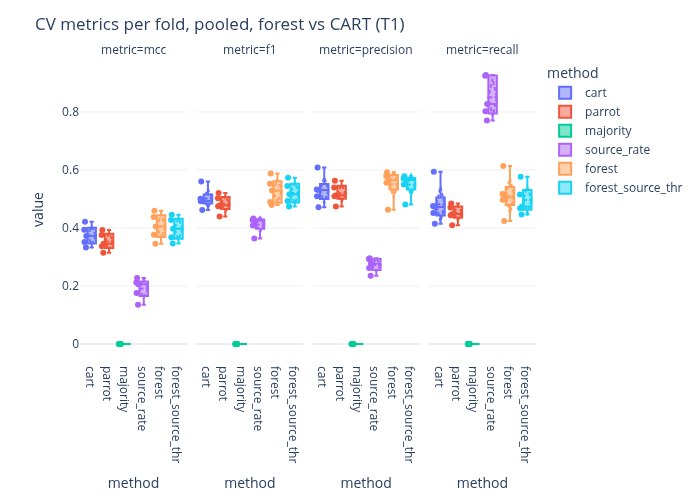

[11/13/26 12:55:44] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_folds_T1.*

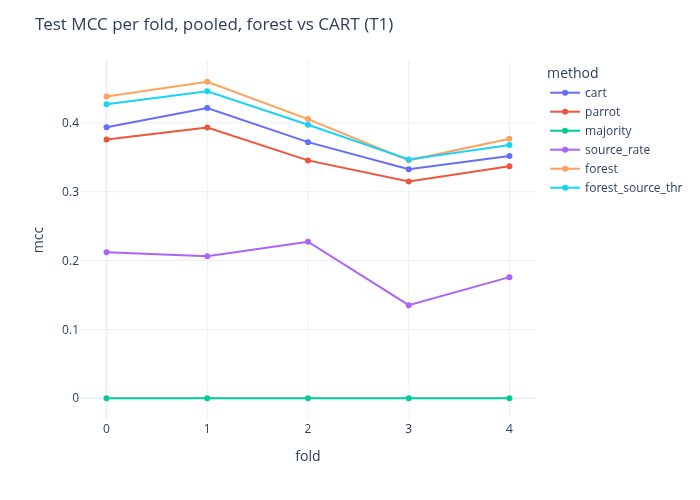

In [21]:
COMPARE = ["forest", "forest_source_thr", "cart", "source_rate", "parrot", "majority"]
for t in TARGETS:
    r = results[t][results[t].method.isin(COMPARE)]
    display(
        Markdown(f"**CV results, pooled, forest vs. CART and the baselines** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(pooled_rows(r), METRICS),
        Markdown(f"**CV results per source, forest vs. CART and the baselines** ({t}, mean +/- std over the 5 test folds)"),
        mean_std(r[r["source"] != "all"], ["mcc", "recall", "precision"], by=("source", "method")),
    )
    long = pooled_rows(r).melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold, pooled, forest vs CART ({t})"), f"forest_cv_box_{t}"))
    display(plots.save(
        px.line(pooled_rows(r), x="fold", y="mcc", color="method", markers=True)
        .update_layout(title=f"Test MCC per fold, pooled, forest vs CART ({t})"),
        f"forest_cv_folds_{t}",
    ))

**Statistical tests.** As in section 5: paired Wilcoxon and A12 = P(forest > other) on the (fold, source) MCC cells with at least 10 test failures; Parrot on T1 only; the constant baselines on the pooled rows only.

In [22]:
for t in TARGETS:
    display(
        Markdown(f"**Forest vs. CART and the other methods** ({t}): paired Wilcoxon and A12 on the (fold, source) MCC cells"),
        show_cells(compare_rows(results[t], "forest", ("forest_source_thr", "cart", *CELL_VS[t]), "test")),
        Markdown(f"**Forest vs. the constant baselines, pooled rows** ({t}): mean test MCC over the 5 folds and folds won"),
        pooled_vs(results[t], "forest", POOLED_VS),
    )


**Forest vs. CART and the other methods** (T2): paired Wilcoxon and A12 on the (fold, source) MCC cells

,test,cells,mean_diff,p,n,min_p,flag,A12
0,forest vs forest_source_thr,62,-0.0303,0.0310,54,0.0e+00,zero_diffs_dropped,0.4152
1,forest vs cart,62,0.0183,0.2001,58,0.0e+00,zero_diffs_dropped,0.5354


**Forest vs. the constant baselines, pooled rows** (T2): mean test MCC over the 5 folds and folds won

,comparison,forest,other,mean_diff,folds_won
0,forest vs source_rate,0.2474,0.1851,0.0624,5/5
1,forest vs majority,0.2474,0.0000,0.2474,5/5


**Forest vs. CART and the other methods** (T1): paired Wilcoxon and A12 on the (fold, source) MCC cells

,test,cells,mean_diff,p,n,min_p,flag,A12
0,forest vs forest_source_thr,63,0.0029,0.5299,56,0.0e+00,zero_diffs_dropped,0.5045
1,forest vs cart,63,0.0313,0.0000,62,0.0e+00,zero_diffs_dropped,0.5635
2,forest vs parrot,63,0.0305,0.0002,63,0.0e+00,NaN,0.5750


**Forest vs. the constant baselines, pooled rows** (T1): mean test MCC over the 5 folds and folds won

,comparison,forest,other,mean_diff,folds_won
0,forest vs source_rate,0.4051,0.1914,0.2138,5/5
1,forest vs majority,0.4051,0.0000,0.4051,5/5


**What the forest uses.** Impurity-decrease importance averaged over the 100 trees, then over the 5 folds, next to CART's mean from section 6. The column draw forces the forest to split on features the single tree never reaches, so its importances are spread more evenly.

**Mean impurity-decrease importance**, forest vs. CART (T2, mean over the 5 folds)

,forest,cart
author_prior_fail_rate,0.123,0.147
fail_rate_7d,0.094,0.020
fail_rate_24h,0.084,0.075
file_fail_prob_max,0.079,0.088
event_pull_request,0.073,0.072
fail_rate_6h,0.068,0.020
event_push,0.058,0.290
days_since_workflow_change,0.050,0.017
churn,0.049,0.035
fail_rate_1h,0.048,0.019


[11/13/26 12:55:49] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/forest_importance_T2.*

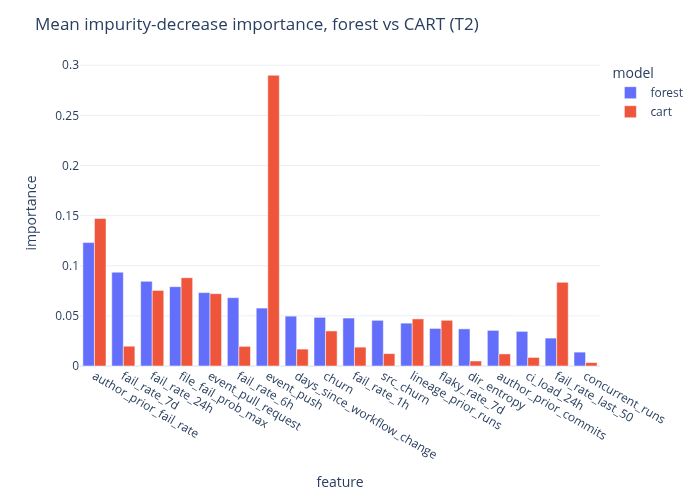

**Mean impurity-decrease importance**, forest vs. CART (T1, mean over the 5 folds)

,forest,cart
fail_streak,0.102,0.321
fail_rate_last_5,0.101,0.194
runs_since_last_fail,0.100,0.016
author_prior_fail_rate,0.094,0.114
file_fail_prob_max,0.083,0.045
fail_rate_12h,0.074,0.087
fail_rate_3h,0.053,0.011
event_pull_request,0.047,0.086
fail_rate_1h,0.039,0.015
additions,0.035,0.019


[11/13/26 12:55:54] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/forest_importance_T1.*

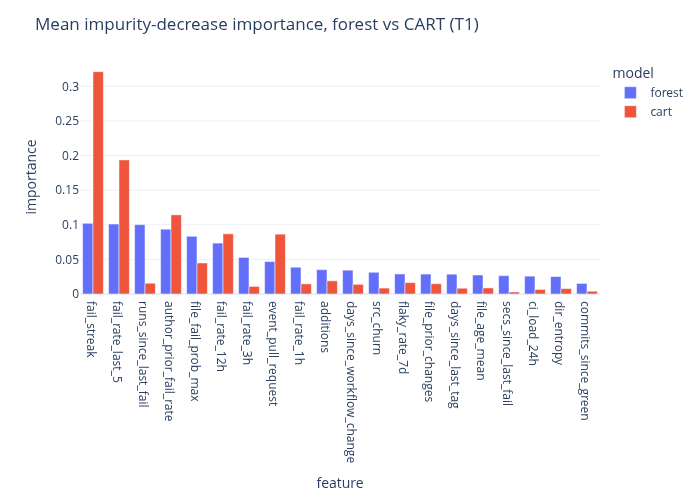

In [23]:
for t in TARGETS:
    imp = pd.DataFrame(
        {
            "forest": np.mean([p["forest"].feature_importances_ for p in rf_payloads[t].values()], axis=0),
            "cart": np.mean([p["tree"].feature_importances_ for p in payloads[t].values()], axis=0),
        },
        index=feats[t],
    ).sort_values("forest", ascending=False)
    display(Markdown(f"**Mean impurity-decrease importance**, forest vs. CART ({t}, mean over the 5 folds)"), imp.round(3))
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")
    display(plots.save(
        px.bar(long, x="feature", y="importance", color="model", barmode="group")
        .update_layout(title=f"Mean impurity-decrease importance, forest vs CART ({t})"),
        f"forest_importance_{t}",
    ))

**Trade-off.** The pooled curve of section 7, for the forest and CART on the same axes. The forest gives almost every run its own P(fail), so its curve is drawn at 201 quantile thresholds. The star is the forest with its tuned per-fold thresholds. As in section 7, the curve uses the test labels and is a diagnosis of the ranking, not a result.

[11/13/26 12:56:03] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_tradeoff_T2.*

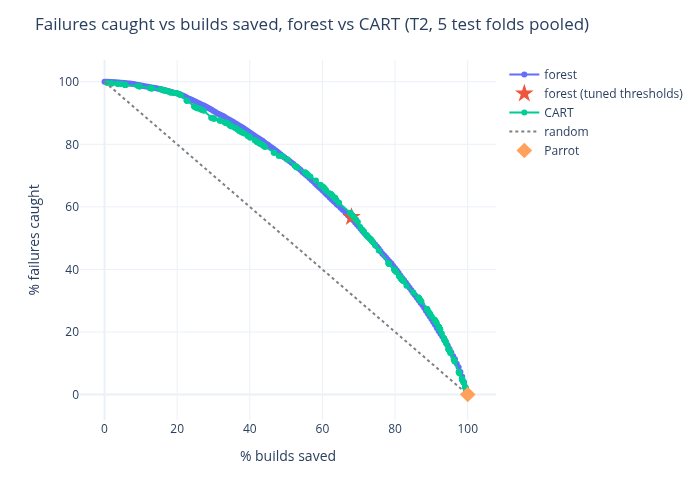

[11/13/26 12:56:13] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_tradeoff_T1.*

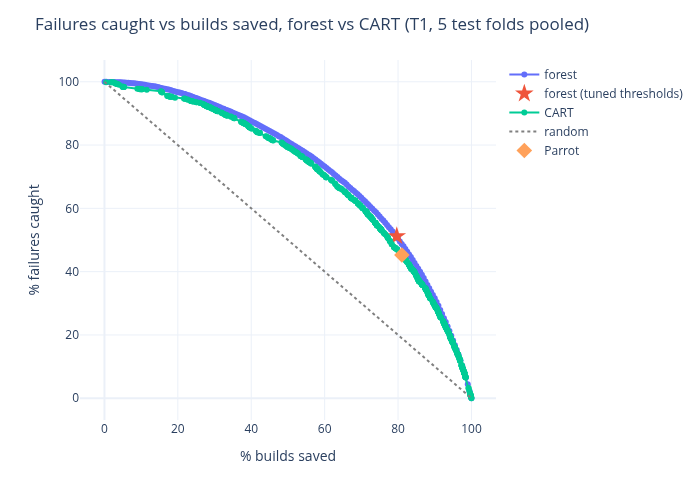

In [24]:
def sweep(proba: np.ndarray, y: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame(
        [{"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)} for th in thresholds]
    )


for t in TARGETS:
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    p_rf = np.concatenate([rf_payloads[t][k]["forest"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    p_cart = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    fig = plots.tradeoff(
        sweep(p_rf, y, np.unique(np.r_[0.0, np.quantile(p_rf, np.linspace(0, 1, 201))])),
        point(pooled(t, "forest")),
        "forest (tuned thresholds)",
    )
    fig.data[0].update(name="forest", showlegend=True)
    c = sweep(p_cart, y, np.unique(np.r_[0.0, p_cart]))
    fig.add_scatter(x=c.saved, y=c.caught, mode="lines+markers", name="CART")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved, forest vs CART ({t}, 5 test folds pooled)"), f"forest_tradeoff_{t}"))

## 10. Save the results

The CV rows (pooled and per source, every method) and the E1/E3 rows go to `results/model/`, where `validation.ipynb` reads them next to the re-test.

In [25]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
for t in TARGETS:
    print(results[t].to_csv(MODEL_DIR / f"cv_results_{t}_{DATASET}.csv", index=False) or f"cv_results_{t}_{DATASET}.csv")
e_results.to_csv(MODEL_DIR / f"e_results_{E_T}_{DATASET}.csv", index=False)
print(f"e_results_{E_T}_{DATASET}.csv")

cv_results_T2_pool-67fa17e1.csv
cv_results_T1_pool-67fa17e1.csv
e_results_T2_pool-67fa17e1.csv


## Observations

- **Implementation.** Our CART gives the same predictions as sklearn's tree on the same inputs. In CV the two are level on T2 (62 cells, mean difference -0.0003, p = 0.80). The best dev grid point is a depth-6 tree with validation MCC 0.41. In CV, every T2 fold chooses balanced class weights, and most choose depth 10.
- **T2, pooled.** CART reaches an MCC of 0.223 +/- 0.053, against 0.185 for `source_rate`. Parrot and majority score 0, since every T2 run follows a pass. CART beats `source_rate` in 4 of 5 folds and majority in all 5. It flags about 29% of the runs and catches 54% of the failures. The forest reaches 0.247, but its lead over CART on the cells is not significant (p = 0.20, A12 = 0.54).
- **T1, pooled.** CART (0.374) is level with Parrot (0.353): p = 0.84, A12 = 0.52 on the cells. The tree mostly re-learns the previous outcome. The forest (0.405) beats both CART (p < 0.001, A12 = 0.56) and Parrot (p = 0.0002, A12 = 0.58).
- **Over time.** Test MCC drops in the last two folds (0.151, 0.183, against 0.25-0.27 in the first three). The validation MCC that each fold is tuned on falls too (0.31 -> 0.21). The later months fail less often (see `eda.ipynb`), so a failure is harder to find among them.
- **Per-source thresholds** lower the pooled MCC (T2: 0.161 vs. 0.223; forest variant p = 0.031). Equalising the flag rate per source discards the difference in base rates, which is part of the signal.
- **What the tree uses.** `event_push` is the root of the T2 tree, with mean importance 0.29 (only 0.10 in the first fold). The next features are `author_prior_fail_rate` (0.15), `file_fail_prob_max` and `fail_rate_last_50`. Windmill and n8n master only have pushes, so part of `event_push` stands for the source. In the forest, which draws features at random, `event_push` falls to 0.06 and the importance spreads over the failure-rate windows. On T1, `fail_streak` and `fail_rate_last_5` swap the lead: the first leads in the last three folds, the second in the first two. Both carry the Parrot signal.
- **Errors per source.** The errors concentrate on a few sources. n8n 33322401 has 9,335 false positives for 3,537 true positives: its pull-request runs fail often, so the tree flags many of them. gh-aw (3 of 157 failures caught) and both windmill workflows (9 and 5 caught) are almost never flagged, since their failures come in streaks that T2 removes or at very low base rates.
- **Transfer (E1-E3).** The pooled model is level with per-source models (E2 - E1: -0.0001, p = 0.96). Leaving the source's repository out costs 0.024 MCC (E3 - E1: p = 0.009, A12 = 0.40). The cost is largest for n8n 33322401 (-0.176), the biggest source. Small sources (fd, tokio, svelte) do better with the pooled or leave-out models than with their own: they have too few runs to train a tree alone.